In [1]:

# Import libraries for DBSCAN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# Load the processed customer features and metadata
X_processed = pd.read_csv("../data/processed/customer_features.csv")
metadata = pd.read_csv("../data/processed/customer_metadata.csv")

print("Feature matrix shape:", X_processed.shape)
print("Metadata shape:", metadata.shape)


Feature matrix shape: (7043, 45)
Metadata shape: (7043, 2)


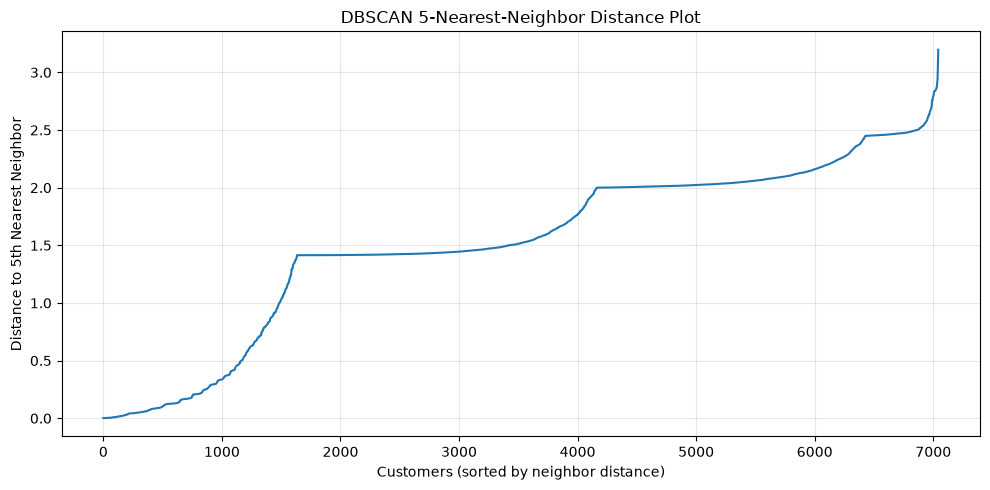

5th-neighbor distance percentiles:
0.50    1.519
0.75    2.039
0.90    2.350
0.95    2.468
0.99    2.660
dtype: float64


In [2]:

# Calculate distances to each customer's 5 nearest neighbors
neighbors = NearestNeighbors(n_neighbors=5, metric="euclidean")
neighbors.fit(X_processed)

distances, _ = neighbors.kneighbors(X_processed)

# The last column contains the distance to the 5th nearest neighbor
k_distances = np.sort(distances[:, -1])

# Plot the sorted distances
plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title("DBSCAN 5-Nearest-Neighbor Distance Plot")
plt.xlabel("Customers (sorted by neighbor distance)")
plt.ylabel("Distance to 5th Nearest Neighbor")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print reference percentiles to help interpret the plot
print("5th-neighbor distance percentiles:")
print(
    pd.Series(k_distances)
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(3)
)


In [3]:

# Test several DBSCAN eps values
eps_values = [1.5, 2.0, 2.3, 2.5]
min_samples_value = 5

dbscan_results = []

for eps_value in eps_values:
    model = DBSCAN(
        eps=eps_value,
        min_samples=min_samples_value,
        metric="euclidean",
        n_jobs=-1
    )

    labels = model.fit_predict(X_processed)

    # Count clusters, excluding the noise label -1
    cluster_ids = set(labels)
    n_clusters = len(cluster_ids - {-1})
    n_noise = int(np.sum(labels == -1))
    noise_percentage = n_noise / len(labels) * 100

    # Calculate silhouette only if at least 2 clusters remain
    # and not every point is its own cluster/noise.
    if 2 <= n_clusters and n_noise < len(labels):
        non_noise_mask = labels != -1
        non_noise_labels = labels[non_noise_mask]

        if len(set(non_noise_labels)) >= 2:
            score = silhouette_score(
                X_processed.loc[non_noise_mask],
                non_noise_labels,
                sample_size=min(2000, int(non_noise_mask.sum())),
                random_state=42
            )
        else:
            score = np.nan
    else:
        score = np.nan

    dbscan_results.append({
        "eps": eps_value,
        "min_samples": min_samples_value,
        "clusters": n_clusters,
        "noise_customers": n_noise,
        "noise_percentage": round(noise_percentage, 2),
        "silhouette_non_noise": (
            round(score, 4) if not np.isnan(score) else np.nan
        )
    })

results_df = pd.DataFrame(dbscan_results)
print(results_df.to_string(index=False))


 eps  min_samples  clusters  noise_customers  noise_percentage  silhouette_non_noise
 1.5            5        25             2820             40.04                0.0273
 2.0            5        29             1935             27.47               -0.0026
 2.3            5         5              218              3.10                0.1296
 2.5            5         4               53              0.75                0.1708


In [4]:

# Test different combinations of eps and min_samples
parameter_combinations = [
    (2.3, 5),
    (2.3, 10),
    (2.3, 15),
    (2.5, 5),
    (2.5, 10),
    (2.5, 15)
]

tuning_results = []

for eps_value, min_samples_value in parameter_combinations:
    model = DBSCAN(
        eps=eps_value,
        min_samples=min_samples_value,
        metric="euclidean",
        n_jobs=-1
    )

    labels = model.fit_predict(X_processed)

    # Count clusters, excluding noise label -1
    cluster_ids = set(labels)
    n_clusters = len(cluster_ids - {-1})
    n_noise = int(np.sum(labels == -1))
    noise_percentage = n_noise / len(labels) * 100

    # Calculate silhouette for non-noise customers when possible
    non_noise_mask = labels != -1
    non_noise_labels = labels[non_noise_mask]

    score = np.nan

    if (
        n_clusters >= 2
        and len(non_noise_labels) > n_clusters
    ):
        score = silhouette_score(
            X_processed.loc[non_noise_mask],
            non_noise_labels,
            sample_size=min(2000, int(non_noise_mask.sum())),
            random_state=42
        )

    tuning_results.append({
        "eps": eps_value,
        "min_samples": min_samples_value,
        "clusters": n_clusters,
        "noise_customers": n_noise,
        "noise_percentage": round(noise_percentage, 2),
        "silhouette_non_noise": (
            round(score, 4) if not np.isnan(score) else np.nan
        )
    })

tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.to_string(index=False))


 eps  min_samples  clusters  noise_customers  noise_percentage  silhouette_non_noise
 2.3            5         5              218              3.10                0.1296
 2.3           10         5              523              7.43                0.1272
 2.3           15         6              855             12.14                0.1059
 2.5            5         4               53              0.75                0.1708
 2.5           10         4              108              1.53                0.1768
 2.5           15         4              170              2.41                0.1702


In [5]:

# Fit DBSCAN using the selected candidate parameters
dbscan_model = DBSCAN(
    eps=2.5,
    min_samples=10,
    metric="euclidean",
    n_jobs=-1
)

dbscan_labels = dbscan_model.fit_predict(X_processed)

# Attach cluster labels to the customer metadata
dbscan_results = metadata.copy()
dbscan_results["Cluster"] = dbscan_labels

# Count customers in each cluster, including noise (-1)
print("DBSCAN cluster sizes (-1 represents noise):")
print(
    dbscan_results["Cluster"]
    .value_counts()
    .sort_index()
)

# Report the noise percentage
noise_count = int((dbscan_labels == -1).sum())
noise_percentage = noise_count / len(dbscan_labels) * 100

print(f"\nNoise customers: {noise_count}")
print(f"Noise percentage: {noise_percentage:.2f}%")


DBSCAN cluster sizes (-1 represents noise):
Cluster
-1     108
 0    4403
 1    1474
 2    1006
 3      52
Name: count, dtype: int64

Noise customers: 108
Noise percentage: 1.53%


In [6]:

# Load original customer data for interpretation
dbscan_profile = pd.read_csv(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Add DBSCAN cluster assignments
dbscan_profile["Cluster"] = dbscan_labels

# Convert TotalCharges to numeric
dbscan_profile["TotalCharges"] = pd.to_numeric(
    dbscan_profile["TotalCharges"],
    errors="coerce"
).fillna(0)

# Separate ordinary clusters from noise for the profile
print("Average characteristics by DBSCAN cluster:")
print(
    dbscan_profile[dbscan_profile["Cluster"] != -1]
    .groupby("Cluster")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
    .mean()
    .round(2)
)

# Calculate observed churn rates, including noise as a separate group
print("\nObserved churn rate by cluster (%):")
print(
    dbscan_profile.groupby("Cluster")["Churn"]
    .apply(lambda values: (values == "Yes").mean() * 100)
    .round(2)
)

# Show churn counts for every cluster and the noise group
print("\nChurn counts by cluster:")
print(
    pd.crosstab(
        dbscan_profile["Cluster"],
        dbscan_profile["Churn"]
    )
)


Average characteristics by DBSCAN cluster:
         tenure  MonthlyCharges  TotalCharges
Cluster                                      
0         32.87           75.53       2689.84
1         30.18           21.05        653.09
2         31.61           83.84       2863.86
3         41.10           21.90        932.30

Observed churn rate by cluster (%):
Cluster
-1    10.19
 0    29.12
 1     7.33
 2    46.02
 3     9.62
Name: Churn, dtype: float64

Churn counts by cluster:
Churn      No   Yes
Cluster            
-1         97    11
 0       3121  1282
 1       1366   108
 2        543   463
 3         47     5


## DBSCAN Clustering — Summary

### Objective
Applied DBSCAN to identify density-based customer segments and customers that did not belong to any sufficiently dense cluster.

### Methodology
- Loaded the same 45 processed customer features used by K-Means and hierarchical clustering.
- Used a 5-nearest-neighbor distance plot to guide the choice of candidate `eps` values.
- Tested multiple `eps` and `min_samples` combinations.
- Selected `eps = 2.5` and `min_samples = 10` for further inspection.
- Evaluated cluster counts, noise percentage, non-noise silhouette score, numerical characteristics, and observed churn rates.

### Results

| Cluster | Customers | Average Tenure (months) | Average Monthly Charges | Observed Churn Rate |
|---|---:|---:|---:|---:|
| 0 | 4,403 | 32.87 | 75.53 | 29.12% |
| 1 | 1,474 | 30.18 | 21.05 | 7.33% |
| 2 | 1,006 | 31.61 | 83.84 | 46.02% |
| 3 | 52 | 41.10 | 21.90 | 9.62% |
| Noise (-1) | 108 | — | — | 10.19% |

### Evaluation
- Number of clusters: 4
- Noise customers: 108 (1.53%)
- Sampled silhouette score on non-noise customers: 0.1768

The silhouette score excludes noise points and should not be compared directly with scores calculated across all observations for K-Means and hierarchical clustering.

### Business Interpretation
Cluster 2 had the highest observed churn rate at 46.02% and the highest average monthly charges, making it a useful segment for further retention analysis. Cluster 1 had substantially lower monthly charges and a 7.33% observed churn rate.

Cluster 0 was the largest and had a churn rate of 29.12%. Cluster 3 was small and should be interpreted cautiously. Noise points were treated as a separate group rather than assumed to be errors or problematic customers.

### Limitations
- DBSCAN is sensitive to `eps`, `min_samples`, feature representation, and distance metric.
- A large cluster may contain customers with different underlying characteristics.
- The noise group is not necessarily anomalous.
- Observed churn differences do not establish causal relationships.
- The chosen parameters are candidates from a limited search, not proven global optima.

### Conclusion
DBSCAN identified four customer clusters and a small noise group. Its segments show useful differences in observed churn rates, but its results must be evaluated alongside K-Means and hierarchical clustering before selecting a final model.